<a href="https://colab.research.google.com/github/FrankEHA/INGENIERIA_DEL_CONOCIMIENTO/blob/main/Proyecto_CNN_Cassava_12_Fases.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Proyecto Final: Pipeline CNN Completo
## 🌿 Diagnóstico de Enfermedades en Hojas de Yuca (Cassava) — Del Problema al Despliegue

**Curso:** IS056B — Ingeniería del Conocimiento
**Docente:** Msc. Jaime Antonio Huaytalla Pariona
**Universidad:** UNCP — Facultad de Ingeniería de Sistemas
**Semestre:** 2026-II | **Unidad:** I — Machine Learning y Redes Neuronales Profundas

**Integrantes:**
| Apellidos y Nombres | Código |
|---|---|
| *TODO* | *TODO* |
| *TODO* | *TODO* |
| *TODO* | *TODO* |
| *TODO* | *TODO* |

---

### 📋 Objetivo
Construir un **pipeline profesional completo de 12 fases** (S05 Arquitecturas CNN, S06 Optimización, S07 Evaluación y Explicabilidad, S08 Producción) para resolver un problema real: **identificar automáticamente la enfermedad presente en una hoja de yuca a partir de una foto tomada con celular**, y desplegar el modelo como un **servicio web (API REST con Flask)** y como modelo ligero para móviles (**TFLite**).

### 📌 Instrucciones de ejecución
1. En Colab: **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)**.
2. Tener a la mano el archivo `kaggle.json` (ver Fase 2) y haber aceptado las reglas de la competencia en Kaggle.
3. Ejecutar las celdas en orden (**Restart & Run All** al finalizar).
4. Completar las secciones marcadas con `TODO` con los resultados obtenidos.

---
## ⚙️ Fase 0: Configuración del Entorno

In [13]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import os, json, datetime, platform, logging, shutil, hashlib, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve,
                             auc, roc_auc_score, f1_score, accuracy_score)
from sklearn.preprocessing import label_binarize

# Verificar GPU
print(f"TensorFlow: {tf.__version__}")
print(f"GPU disponible: {tf.config.list_physical_devices('GPU')}")

# Reproducibilidad (Fase 11: semillas fijadas)
SEED = 42
tf.keras.utils.set_random_seed(SEED)   # fija semillas de Python, NumPy y TensorFlow
np.random.seed(SEED)

# Configuración global
IMG_SIZE = (192, 192)   # Las fotos originales son de 800x600. 192 equilibra detalle y tiempo en una T4.
                        # Si Colab va muy lento, bajar a (160, 160); si hay tiempo, subir a (224, 224).
BATCH_SIZE = 32
NUM_CLASSES = 5         # Cassava: 4 enfermedades + hoja sana

# Estructura del proyecto (Fase 9: versionado)
PROJECT_DIR = '/content/proyecto_cassava'
RAW_DIR = f'{PROJECT_DIR}/data/raw'              # datos crudos tal como vienen de Kaggle
PROCESSED_DIR = f'{PROJECT_DIR}/data/processed'  # imágenes redimensionadas y divididas
for d in [RAW_DIR, PROCESSED_DIR, f'{PROJECT_DIR}/src/models', f'{PROJECT_DIR}/src/training',
          f'{PROJECT_DIR}/experiments', f'{PROJECT_DIR}/models/production']:
    os.makedirs(d, exist_ok=True)
os.chdir(PROJECT_DIR)   # todas las rutas relativas (experiments/, models/) cuelgan de aquí

plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 150
print(f"📁 Directorio del proyecto: {os.getcwd()}")
print("✅ Entorno configurado correctamente")

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
📁 Directorio del proyecto: /content/proyecto_cassava
✅ Entorno configurado correctamente


---
## 📝 Fase 1: Definición del Problema

Antes de escribir código, respondemos las 5 preguntas clave:

### Ficha de Proyecto

| Pregunta | Nuestra Respuesta |
|---|---|
| ¿Qué problema resuelve este modelo? | Diagnóstico temprano de enfermedades de la yuca a partir de una foto de la hoja. Hoy el diagnóstico depende de que un técnico agrícola visite la parcela: es lento, costoso y escaso. Un modelo que clasifique la foto permite actuar antes de que la enfermedad se propague y destruya la cosecha. La yuca es un cultivo de seguridad alimentaria (2.ª fuente de carbohidratos en África) y también se cultiva en la selva peruana. |
| ¿Es clasificación binaria o multiclase? | **Multiclase (5 clases):** Añublo bacteriano (CBB), Rayado marrón (CBSD), Moteado verde (CGM), Mosaico (CMD) y Hoja sana (Healthy). Cada imagen pertenece a una sola clase. |
| ¿Cuál es la métrica principal de éxito? ¿Por qué? | **F1-score macro.** El dataset está muy desbalanceado (CMD tiene más de la mitad de las imágenes): un modelo que siempre diga "CMD" tendría accuracy alta sin servir para nada. El F1 macro promedia el desempeño de las 5 clases por igual, así que castiga ignorar las clases minoritarias. Como métricas secundarias se reportan Accuracy y Macro AUC. |
| ¿Cuáles son las restricciones del proyecto? | Los agricultores usan **celulares de gama baja con poca conectividad**: el modelo final debe pesar **< 10 MB** (versión TFLite para móvil) y responder rápido. Las fotos son de campo (fondos, sombras, varias hojas), no de laboratorio. Además debe exponerse como **API REST** para integrarse con una app o web. Recursos de entrenamiento: GPU T4 gratuita de Colab. |
| ¿Cuál es el baseline (clasificador trivial)? | **Aleatorio:** 1/5 = **20%** de accuracy. **Clase mayoritaria** (siempre "CMD"): ≈ **61%** de accuracy pero F1 macro ≈ 0.15. Nuestro modelo debe superar claramente ambos, sobre todo en F1 macro. |

> 💡 **Fuente del dataset:** *Cassava Leaf Disease Classification* (Kaggle, 2020). 21,397 imágenes recolectadas en Uganda por agricultores con sus celulares y etiquetadas por expertos del National Crops Resources Research Institute (NaCRRI) y el AI Lab de Makerere University. Aunque proviene de Uganda, el añublo bacteriano (CBB) también afecta a la yuca en América Latina, y la metodología es replicable para cultivos de la selva peruana.

---
## 🔍 Fase 2: Selección del Dataset y EDA

**Justificación del dataset** (criterios de la Fase 2):
- ✅ Más de 1,000 imágenes → **21,397**
- ✅ Al menos 3 clases → **5 clases**
- ✅ Aplicación real → diagnóstico agrícola con fotos de celular tomadas en campo

### Descarga desde Kaggle
1. En la página de la competencia (*Cassava Leaf Disease Classification*), pestaña **Rules → "I Understand and Accept"**.
2. En Kaggle: foto de perfil → **Settings → API → Create New Token** → se descarga `kaggle.json`.
3. Ejecutar la celda siguiente y subir `kaggle.json` cuando se abra el selector.

> ⚠️ `kaggle.json` es una credencial personal: **no** la suban a GitHub ni la dejen escrita en el notebook.

In [14]:
# Configurar la API de Kaggle (token nuevo KGAT_..., guardado en Secretos de Colab)
!pip install -q --upgrade kaggle          # la versión nueva entiende este tipo de token
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

# Prueba rápida de conexión
!kaggle competitions list -s cassava
print("✅ Credenciales de Kaggle listas")

ref                                                                      deadline             category       reward  teamCount  userHasEntered  userRank  
-----------------------------------------------------------------------  -------------------  ---------  ----------  ---------  --------------  --------  
https://www.kaggle.com/competitions/cassava-leaf-disease-classification  2021-02-18 23:59:00  Research   18,000 Usd       3900            True         0  
https://www.kaggle.com/competitions/cassava-disease                      2019-06-01 23:59:00  Community       Kudos         86           False         0  
https://www.kaggle.com/competitions/ammi-2020-convnets                   2020-05-10 23:59:00  Community       Kudos         34           False         0  
https://www.kaggle.com/competitions/ammi-2022-convnets                   2022-04-17 23:00:00  Community       Kudos         21           False         0  
https://www.kaggle.com/competitions/ammi-2023-convnets                

In [15]:
# Descargar la competencia y descomprimir SOLO lo necesario (train_images + train.csv + mapa de etiquetas)
# El zip completo (~6 GB) incluye las mismas imágenes en TFRecords y un test sin etiquetas que no usaremos.
data_dir = f'{RAW_DIR}/train_images'
zip_path = f'{RAW_DIR}/cassava-leaf-disease-classification.zip'

if os.path.exists(data_dir) and len(os.listdir(data_dir)) > 20000:
    print(f"✅ Dataset ya disponible en {data_dir}")
else:
    print("Descargando desde Kaggle... (puede tardar varios minutos)")
    !kaggle competitions download -c cassava-leaf-disease-classification -p {RAW_DIR}
    if not os.path.exists(zip_path):
        raise RuntimeError("No se descargó el zip. Verifique que aceptó las reglas de la competencia "
                           "en Kaggle (pestaña Rules) y que kaggle.json es correcto.")
    print("Descomprimiendo...")
    !unzip -q -o {zip_path} "train_images/*" train.csv label_num_to_disease_map.json -d {RAW_DIR}
    os.remove(zip_path)   # liberar espacio en disco
    print("✅ Descarga y descompresión completadas")

print(f"Imágenes en train_images: {len(os.listdir(data_dir))}")

Descargando desde Kaggle... (puede tardar varios minutos)
100% 5.76G/5.76G [04:53<00:00, 21.1MB/s]

Descomprimiendo...
✅ Descarga y descompresión completadas
Imágenes en train_images: 21397


In [16]:
# Cargar etiquetas
df = pd.read_csv(f'{RAW_DIR}/train.csv')
with open(f'{RAW_DIR}/label_num_to_disease_map.json') as f:
    label_map = {int(k): v for k, v in json.load(f).items()}

# Nombres cortos para gráficos y carpetas (el orden alfabético coincide con las etiquetas 0-4)
CLASS_NAMES = ['CBB', 'CBSD', 'CGM', 'CMD', 'Healthy']
CLASS_DESCRIPTIONS = {
    'CBB':     'Cassava Bacterial Blight — Añublo bacteriano',
    'CBSD':    'Cassava Brown Streak Disease — Rayado marrón (virus)',
    'CGM':     'Cassava Green Mottle — Moteado verde',
    'CMD':     'Cassava Mosaic Disease — Mosaico de la yuca (virus)',
    'Healthy': 'Hoja sana',
}
df['class_name'] = df['label'].map(lambda i: CLASS_NAMES[i])

print("Mapa oficial de etiquetas:")
for k, v in label_map.items():
    print(f"  {k} → {CLASS_NAMES[k]:<8} | {v}")
df.head()

Mapa oficial de etiquetas:
  0 → CBB      | Cassava Bacterial Blight (CBB)
  1 → CBSD     | Cassava Brown Streak Disease (CBSD)
  2 → CGM      | Cassava Green Mottle (CGM)
  3 → CMD      | Cassava Mosaic Disease (CMD)
  4 → Healthy  | Healthy


,image_id,label,class_name
0,1000015157.jpg,0,CBB
1,1000201771.jpg,3,CMD
2,100042118.jpg,1,CBSD
3,1000723321.jpg,1,CBSD
4,1000812911.jpg,3,CMD


### 2.1 Distribución de Clases

Total de clases: 5
Total de imágenes: 21397
Clase más grande: CMD (13158)
Clase más pequeña: CBB (1087)


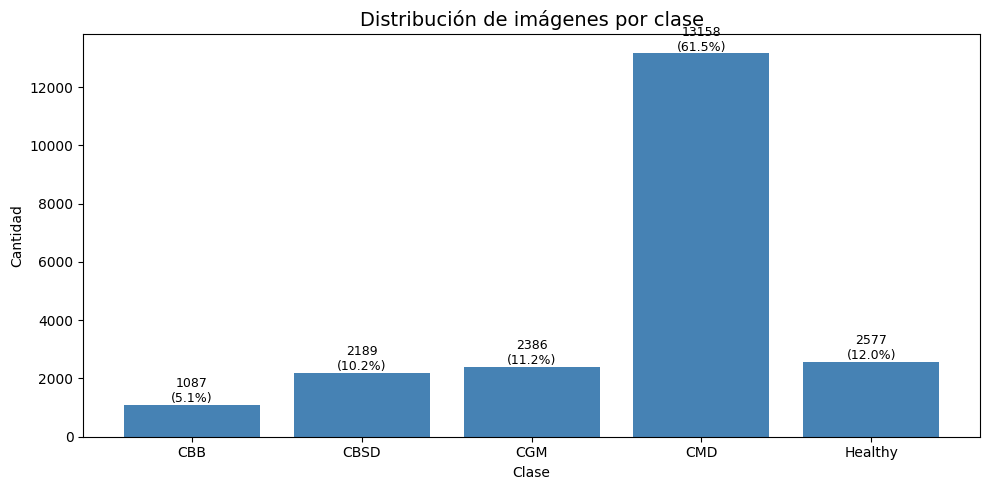


Ratio de desbalance: 12.1:1
Baseline 'clase mayoritaria' (accuracy): 61.5%
Baseline aleatorio (accuracy): 20.0%


In [17]:
# Contar imágenes por clase
class_counts = df['class_name'].value_counts().reindex(CLASS_NAMES).to_dict()

print(f"Total de clases: {len(class_counts)}")
print(f"Total de imágenes: {sum(class_counts.values())}")
print(f"Clase más grande: {max(class_counts, key=class_counts.get)} ({max(class_counts.values())})")
print(f"Clase más pequeña: {min(class_counts, key=class_counts.get)} ({min(class_counts.values())})")

# Visualizar distribución
plt.figure(figsize=(10, 5))
bars = plt.bar(class_counts.keys(), class_counts.values(), color='steelblue')
for b, v in zip(bars, class_counts.values()):
    plt.text(b.get_x() + b.get_width()/2, v + 100, f"{v}\n({v/sum(class_counts.values()):.1%})",
             ha='center', fontsize=9)
plt.title('Distribución de imágenes por clase', fontsize=14)
plt.xlabel('Clase')
plt.ylabel('Cantidad')
plt.tight_layout()
plt.show()

# Ratio de desbalance
max_c = max(class_counts.values())
min_c = min(class_counts.values())
print(f"\nRatio de desbalance: {max_c/min_c:.1f}:1")
print(f"Baseline 'clase mayoritaria' (accuracy): {max_c/sum(class_counts.values()):.1%}")
print(f"Baseline aleatorio (accuracy): {1/len(class_counts):.1%}")

### 📝 Análisis de la distribución
*TODO: Comentar el desbalance observado (ratio, clase dominante) y cómo lo abordamos: división estratificada, `class_weight` en el entrenamiento y F1 macro como métrica principal.*

### 2.2 Propiedades de las Imágenes

In [18]:
# Analizar propiedades de una muestra de imágenes (50 por clase)
widths, heights, channels, file_sizes = [], [], [], []
for class_name in CLASS_NAMES:
    sample = df[df['class_name'] == class_name].sample(50, random_state=SEED)
    for img_name in sample['image_id']:
        try:
            path = os.path.join(data_dir, img_name)
            img = Image.open(path)
            widths.append(img.width)
            heights.append(img.height)
            channels.append(len(img.getbands()))
            file_sizes.append(os.path.getsize(path) / 1024)
        except Exception:
            pass

print(f"Ancho: [{min(widths)}, {max(widths)}], promedio: {np.mean(widths):.0f}")
print(f"Alto: [{min(heights)}, {max(heights)}], promedio: {np.mean(heights):.0f}")
print(f"Canales: {Counter(channels)}")
print(f"Aspecto promedio: {np.mean(widths)/np.mean(heights):.2f}")
print(f"Peso promedio por archivo: {np.mean(file_sizes):.0f} KB")

Ancho: [800, 800], promedio: 800
Alto: [600, 600], promedio: 600
Canales: Counter({3: 250})
Aspecto promedio: 1.33
Peso promedio por archivo: 112 KB


### 2.3 Visualización de Muestras

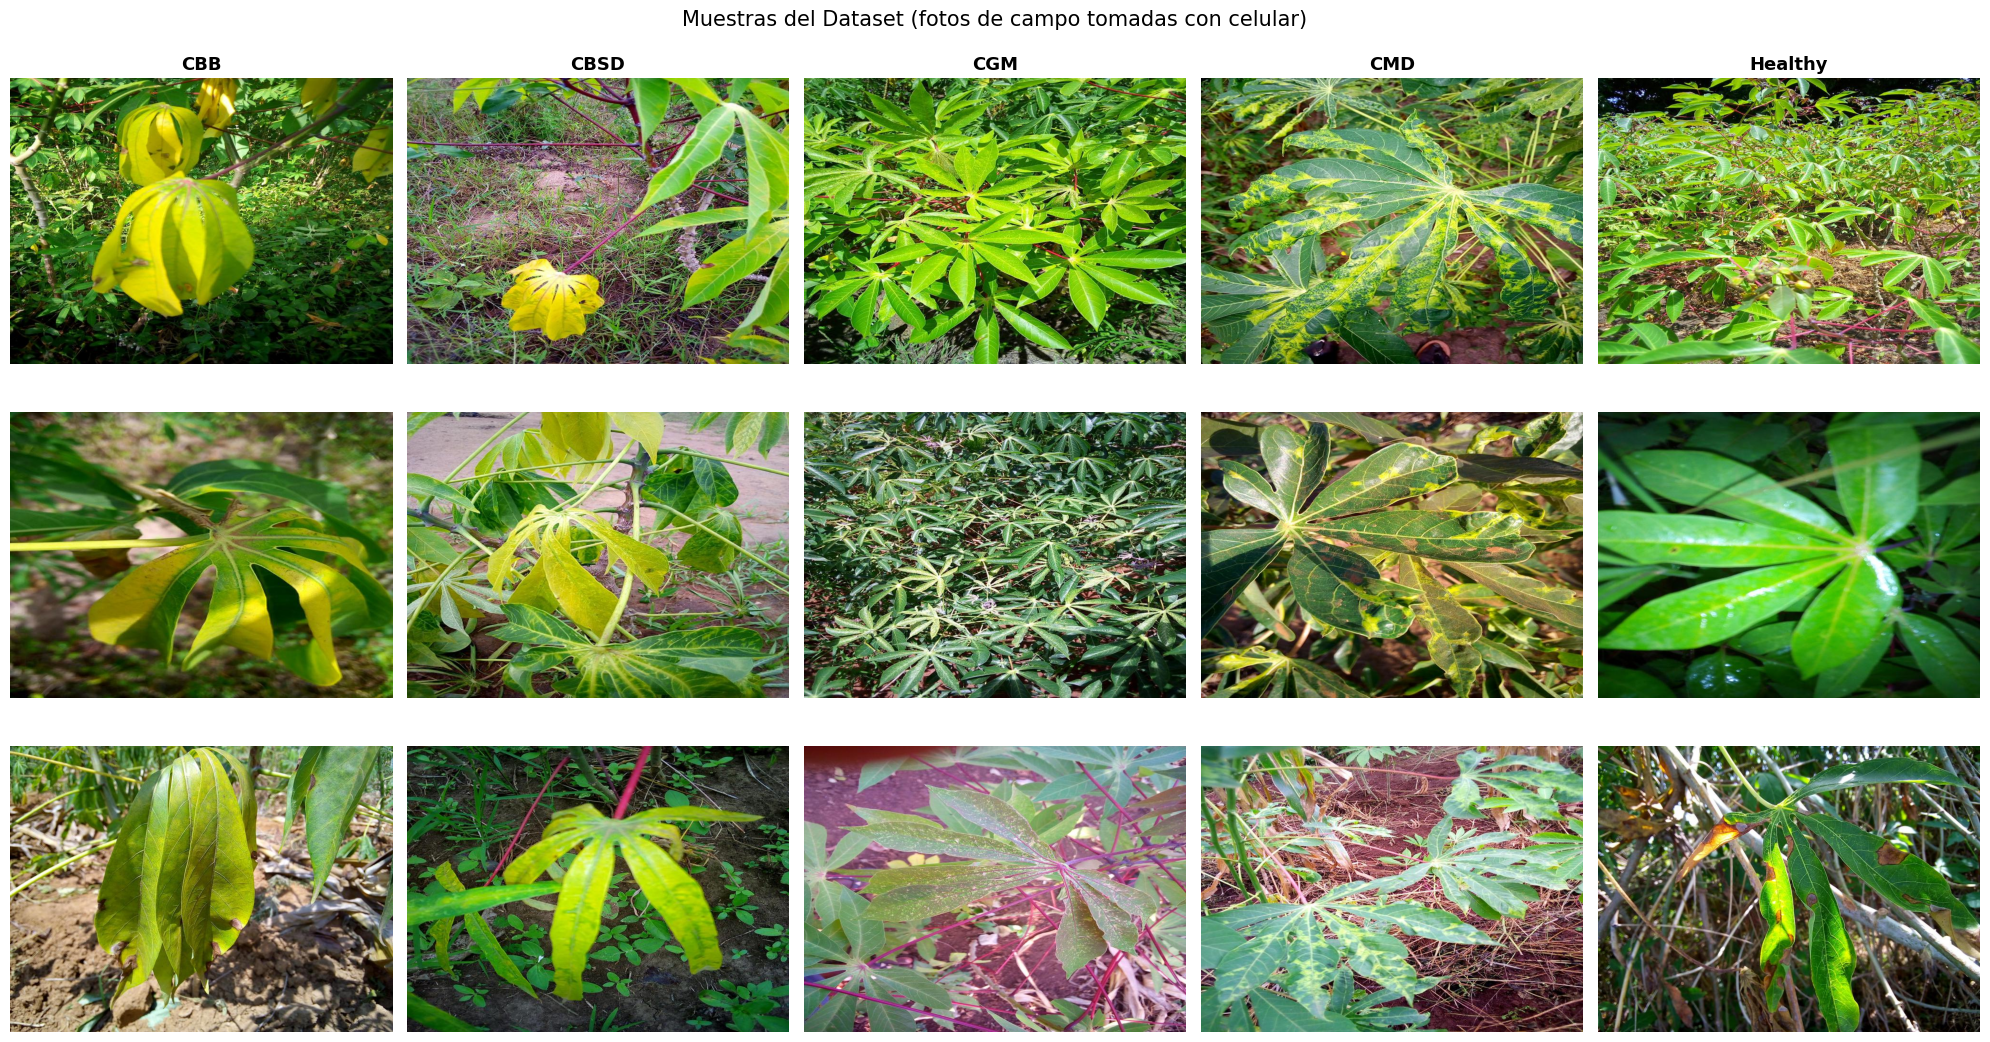

In [19]:
# Mostrar 3 imágenes por clase
fig, axes = plt.subplots(3, len(CLASS_NAMES), figsize=(20, 11))
for i, class_name in enumerate(CLASS_NAMES):
    imgs = df[df['class_name'] == class_name].sample(3, random_state=SEED)['image_id']
    for j, img_name in enumerate(imgs):
        img = Image.open(os.path.join(data_dir, img_name))
        axes[j, i].imshow(img)
        axes[j, i].set_title(class_name if j == 0 else '', fontsize=13, fontweight='bold')
        axes[j, i].axis('off')

plt.suptitle('Muestras del Dataset (fotos de campo tomadas con celular)', fontsize=15)
plt.tight_layout()
plt.show()

### 2.4 Detección de Imágenes Corruptas

In [20]:
def find_corrupted_images(directory):
    corrupted = []
    total = 0
    for root, dirs, files in os.walk(directory):
        for fname in files:
            if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            fpath = os.path.join(root, fname)
            total += 1
            try:
                img = Image.open(fpath)
                img.verify()
            except Exception as e:
                corrupted.append((fpath, str(e)))
    return corrupted, total

corrupted, total = find_corrupted_images(data_dir)
print(f"Imágenes analizadas: {total}")
print(f"Imágenes corruptas: {len(corrupted)} ({len(corrupted)/total*100:.2f}%)")
if corrupted:
    for path, err in corrupted[:5]:
        print(f"  ❌ {path}: {err}")

# Excluir corruptas del DataFrame para no usarlas en el entrenamiento
corrupted_names = {os.path.basename(p) for p, _ in corrupted}
df = df[~df['image_id'].isin(corrupted_names)].reset_index(drop=True)
print(f"Imágenes válidas: {len(df)}")

Imágenes analizadas: 21397
Imágenes corruptas: 0 (0.00%)
Imágenes válidas: 21397


### 2.5 Detección de Duplicados
Si una misma imagen aparece en train y en test, el modelo "hace trampa" (data leakage). Buscamos duplicados exactos con un hash MD5 de cada archivo.

In [21]:
def file_md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

with ThreadPoolExecutor(max_workers=8) as ex:
    df['md5'] = list(ex.map(file_md5, [os.path.join(data_dir, n) for n in df['image_id']]))

dup_mask = df.duplicated('md5', keep='first')
print(f"Duplicados exactos encontrados: {dup_mask.sum()}")
if dup_mask.any():
    conflictos = df[df.duplicated('md5', keep=False)].groupby('md5')['label'].nunique()
    print(f"  De ellos, con etiquetas distintas: {(conflictos > 1).sum()}")
    df = df[~dup_mask].reset_index(drop=True)   # conservar una sola copia
print(f"Imágenes finales para el pipeline: {len(df)}")

Duplicados exactos encontrados: 0
Imágenes finales para el pipeline: 21397


---
## 🔄 Fase 3: Preprocesamiento y Data Augmentation

### 3.0 División estratificada y redimensionado
Las fotos originales pesan bastante (800×600). Las **redimensionamos una sola vez** a `IMG_SIZE` y las guardamos en carpetas por clase (`train/`, `val/`, `test/`). Así:
- Cada época lee archivos pequeños → el entrenamiento es mucho más rápido.
- Podemos usar `image_dataset_from_directory` igual que en el ejemplo.

**División 70 / 15 / 15 estratificada:** cada subconjunto conserva la misma proporción de clases. El conjunto de **test no se toca** hasta la evaluación final (Fase 6). El test oficial de Kaggle está oculto, por eso creamos el nuestro.

In [22]:
# División estratificada 70/15/15
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)

split_summary = pd.DataFrame({
    'train': train_df['class_name'].value_counts(),
    'val':   val_df['class_name'].value_counts(),
    'test':  test_df['class_name'].value_counts(),
}).reindex(CLASS_NAMES)
split_summary.loc['TOTAL'] = split_summary.sum()
print(split_summary)

def resize_and_save(args):
    src, dst = args
    if os.path.exists(dst):
        return
    img = Image.open(src).convert('RGB').resize(IMG_SIZE, Image.BILINEAR)
    img.save(dst, quality=95)

def build_split(split_df, split_name):
    tasks = []
    for name, cls in zip(split_df['image_id'], split_df['class_name']):
        out_dir = os.path.join(PROCESSED_DIR, split_name, cls)
        os.makedirs(out_dir, exist_ok=True)
        tasks.append((os.path.join(data_dir, name), os.path.join(out_dir, name)))
    with ThreadPoolExecutor(max_workers=8) as ex:
        list(ex.map(resize_and_save, tasks))
    print(f"  ✅ {split_name}: {len(tasks)} imágenes")

print(f"\nRedimensionando a {IMG_SIZE} y guardando en {PROCESSED_DIR} ...")
for split_df, split_name in [(train_df, 'train'), (val_df, 'val'), (test_df, 'test')]:
    build_split(split_df, split_name)

            train   val  test
class_name                   
CBB           761   163   163
CBSD         1532   328   329
CGM          1670   358   358
CMD          9210  1974  1974
Healthy      1804   387   386
TOTAL       14977  3210  3210

Redimensionando a (192, 192) y guardando en /content/proyecto_cassava/data/processed ...
  ✅ train: 14977 imágenes
  ✅ val: 3210 imágenes
  ✅ test: 3210 imágenes


### 3.1 Pipeline con `tf.data`

In [23]:
# Pipeline con tf.data (recomendado)
train_dataset = tf.keras.utils.image_dataset_from_directory(
    f'{PROCESSED_DIR}/train', image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    seed=SEED, shuffle=True, label_mode='categorical', class_names=CLASS_NAMES
)
val_dataset = tf.keras.utils.image_dataset_from_directory(
    f'{PROCESSED_DIR}/val', image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    shuffle=False, label_mode='categorical', class_names=CLASS_NAMES
)
test_dataset = tf.keras.utils.image_dataset_from_directory(
    f'{PROCESSED_DIR}/test', image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    shuffle=False, label_mode='categorical', class_names=CLASS_NAMES
)

class_names = train_dataset.class_names
NUM_CLASSES = len(class_names)
test_file_paths = test_dataset.file_paths   # para mostrar imágenes en el análisis de errores
print(f"Clases: {NUM_CLASSES} → {class_names}")

Found 14977 files belonging to 5 classes.
Found 3210 files belonging to 5 classes.
Found 3210 files belonging to 5 classes.
Clases: 5 → ['CBB', 'CBSD', 'CGM', 'CMD', 'Healthy']


In [24]:
# Capas de augmentation y normalización
normalization = tf.keras.layers.Rescaling(1./255)

# Justificación de cada transformación (Guía Estratégica de Data Augmentation):
#  - Flip horizontal y vertical: una hoja fotografiada desde arriba no tiene "arriba" ni "abajo" fijo.
#  - Rotación: las hojas rotan naturalmente en la planta y en la foto.
#  - Zoom: cada agricultor toma la foto a una distancia distinta.
#  - Brillo / contraste: fotos de exterior con sol, sombra o nubes.
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomBrightness(0.15),   # trabaja sobre píxeles en rango [0, 255]
    tf.keras.layers.RandomContrast(0.15),
], name='data_augmentation')

# Aplicar al dataset (augmentation primero, sobre [0,255]; luego normalización a [0,1])
def preprocess_train(images, labels):
    images = data_augmentation(images, training=True)
    images = normalization(images)
    return images, labels

def preprocess_val(images, labels):
    images = normalization(images)
    return images, labels

# ⚠️ IMPORTANTE: Augmentation SOLO en entrenamiento
train_ds = train_dataset.map(preprocess_train, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.shuffle(100).prefetch(tf.data.AUTOTUNE)

# Versión de train SIN augmentation: para el Modelo 3, que ya trae augmentation dentro
# (así evitamos aplicar augmentation dos veces)
train_ds_noaug = train_dataset.map(preprocess_val, num_parallel_calls=tf.data.AUTOTUNE)
train_ds_noaug = train_ds_noaug.shuffle(100).prefetch(tf.data.AUTOTUNE)

val_ds = val_dataset.map(preprocess_val, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

test_ds = test_dataset.map(preprocess_val, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("✅ Pipelines de datos configurados")
print(f"  Train: CON augmentation (Modelos 1 y 2) / SIN augmentation externa (Modelo 3)")
print(f"  Val:   SIN augmentation")
print(f"  Test:  SIN augmentation (solo se usa en la Fase 6)")

✅ Pipelines de datos configurados
  Train: CON augmentation (Modelos 1 y 2) / SIN augmentation externa (Modelo 3)
  Val:   SIN augmentation
  Test:  SIN augmentation (solo se usa en la Fase 6)


In [25]:
# Pesos de clase para compensar el desbalance (clases pequeñas pesan más en la loss)
class_weights_arr = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_df['label'].values)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(class_weights_arr)}
for i, w in CLASS_WEIGHT.items():
    print(f"  {class_names[i]:<8}: peso = {w:.3f}")

  CBB     : peso = 3.936
  CBSD    : peso = 1.955
  CGM     : peso = 1.794
  CMD     : peso = 0.325
  Healthy : peso = 1.660


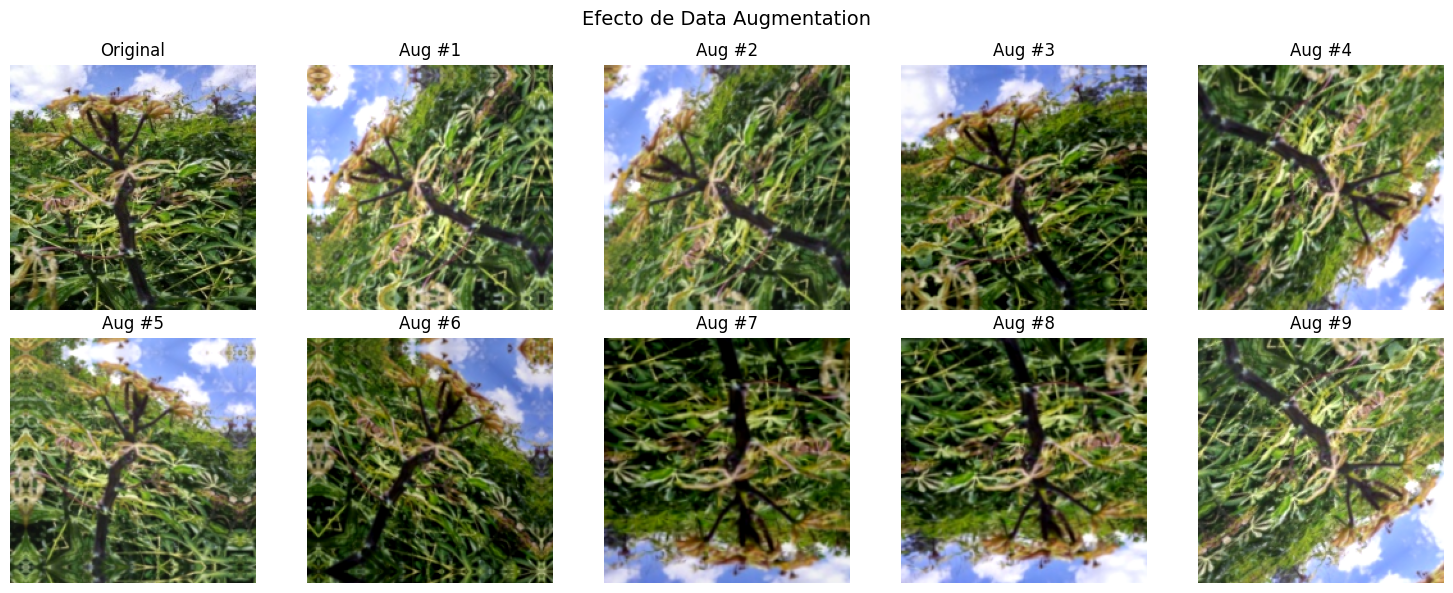

In [26]:
# Visualizar augmentation
sample_batch = next(iter(train_dataset))
sample_img = sample_batch[0][0:1]  # Primera imagen, sin normalizar

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes[0, 0].imshow(sample_img[0].numpy().astype('uint8'))
axes[0, 0].set_title('Original')
axes[0, 0].axis('off')

for i in range(1, 10):
    row, col = i // 5, i % 5
    augmented = data_augmentation(sample_img, training=True)
    axes[row, col].imshow(np.clip(augmented[0].numpy(), 0, 255).astype('uint8'))
    axes[row, col].set_title(f'Aug #{i}')
    axes[row, col].axis('off')

plt.suptitle('Efecto de Data Augmentation', fontsize=14)
plt.tight_layout()
plt.show()

---
## 🏗️ Fase 4: Diseño de 3 Modelos CNN

### Modelo 1: CNN Baseline
Arquitectura simple con 3 bloques Conv+BN+ReLU+MaxPool. **Propósito:** confirmar que el pipeline funciona de principio a fin antes de invertir en arquitecturas complejas.

In [27]:
def build_baseline_model(input_shape, num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        # Bloque 1
        tf.keras.layers.Conv2D(32, (3,3), padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.MaxPooling2D((2,2)),
        # Bloque 2
        tf.keras.layers.Conv2D(64, (3,3), padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.MaxPooling2D((2,2)),
        # Bloque 3
        tf.keras.layers.Conv2D(128, (3,3), padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.GlobalAveragePooling2D(),
        # Clasificador
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(num_classes, activation='softmax')
    ], name='cnn_baseline')
    return model

model_baseline = build_baseline_model((*IMG_SIZE, 3), NUM_CLASSES)
model_baseline.summary()

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 192, 192, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 192, 192, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 192, 192, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 96, 96, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 96, 96, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 48, 48, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 48, 48, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 128,453 (501.77 KB)

 Trainable params: 128,005 (500.02 KB)

 Non-trainable params: 448 (1.75 KB)

### Modelo 2: CNN Mejorada con Bloques Residuales
Aplica skip connections (S05) con Functional API para combatir el desvanecimiento del gradiente.

In [28]:
def residual_block(x, filters, stride=1):
    shortcut = x
    # Rama principal
    x = tf.keras.layers.Conv2D(filters, (3,3), strides=stride, padding='same')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Conv2D(filters, (3,3), padding='same')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    # Ajustar shortcut si cambian dimensiones
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = tf.keras.layers.Conv2D(filters, (1,1), strides=stride, padding='same')(shortcut)
        shortcut = tf.keras.layers.BatchNormalization()(shortcut)
    x = tf.keras.layers.Add()([x, shortcut])
    x = tf.keras.layers.Activation('relu')(x)
    return x

def build_improved_model(input_shape, num_classes):
    inputs = tf.keras.layers.Input(shape=input_shape)
    # Stem
    x = tf.keras.layers.Conv2D(64, (7,7), strides=2, padding='same')(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling2D((3,3), strides=2, padding='same')(x)
    # Bloques residuales
    x = residual_block(x, 64)
    x = residual_block(x, 64)
    x = residual_block(x, 128, stride=2)
    x = residual_block(x, 128)
    x = residual_block(x, 256, stride=2)
    x = residual_block(x, 256)
    # Clasificador
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(512, kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='cnn_improved')

model_improved = build_improved_model((*IMG_SIZE, 3), NUM_CLASSES)
model_improved.summary()

Model: "cnn_improved"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 192, 192,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 96, 96,    │      9,472 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 96, 96,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 96, 96,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 48, 48,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 48, 48,    │     36,928 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 48, 48,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 48, 48,    │     36,928 │ activation_4[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        256 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 48, 48,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 48, 48,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 48, 48,    │     36,928 │ activation_5[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        256 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 48, 48,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 48, 48,    │     36,928 │ activation_6[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        256 │ conv2d_7[0][0]  

 Total params: 2,925,701 (11.16 MB)

 Trainable params: 2,920,197 (11.14 MB)

 Non-trainable params: 5,504 (21.50 KB)

### Modelo 3: CNN Optimizada
Augmentation integrado en el grafo + stem con stride agresivo + regularización L2 + doble dropout (S06).

In [29]:
def build_optimized_model(input_shape, num_classes):
    inputs = tf.keras.layers.Input(shape=input_shape)
    # Augmentation dentro del modelo (solo activo en training; recibe imágenes ya normalizadas en [0,1])
    x = tf.keras.layers.RandomFlip("horizontal_and_vertical")(inputs)
    x = tf.keras.layers.RandomRotation(0.15)(x)
    x = tf.keras.layers.RandomZoom(0.15)(x)
    x = tf.keras.layers.RandomContrast(0.15)(x)
    # Stem con L2
    x = tf.keras.layers.Conv2D(64, (7,7), strides=2, padding='same',
                               kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling2D((3,3), strides=2, padding='same')(x)
    # Bloques residuales
    for filters in [64, 64, 128, 128, 256, 256]:
        stride = 2 if (filters != 64 and x.shape[-1] != filters) else 1
        x = residual_block(x, filters, stride)
    # Clasificador con doble dropout
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(512, kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    x = tf.keras.layers.Dense(256, kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='cnn_optimized')

model_optimized = build_optimized_model((*IMG_SIZE, 3), NUM_CLASSES)
model_optimized.summary()

Model: "cnn_optimized"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 192, 192,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_1       │ (None, 192, 192,  │          0 │ input_layer_3[0]… │
│ (RandomFlip)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation_1   │ (None, 192, 192,  │          0 │ random_flip_1[0]… │
│ (RandomRotation)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom_1       │ (None, 192, 192,  │          0 │ random_rotation_… │
│ (RandomZoom)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_contrast_1   │ (None, 192, 192,  │          0 │ random_zoom_1[0]… │
│ (RandomContrast)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 96, 96,    │      9,472 │ random_contrast_… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 96, 96,    │        256 │ conv2d_18[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_17       │ (None, 96, 96,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 48, 48,    │          0 │ activation_17[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 48, 48,    │     36,928 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        256 │ conv2d_19[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_18       │ (None, 48, 48,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 48, 48,    │     36,928 │ activation_18[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        256 │ conv2d_20[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 48, 48,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_19       │ (None, 48, 48,    │          0 │ add_6[0][0]       │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 48, 48,    │     36,928 │ activation_19[0]

 Total params: 3,055,749 (11.66 MB)

 Trainable params: 3,050,245 (11.64 MB)

 Non-trainable params: 5,504 (21.50 KB)

In [30]:
# Comparar los 3 modelos
print(f"{'Modelo':<25} {'Params':>12} {'Tamaño (MB)':>12}")
print("-" * 50)
for name, m in [("CNN Baseline", model_baseline),
                ("CNN Mejorada", model_improved),
                ("CNN Optimizada", model_optimized)]:
    params = m.count_params()
    size_mb = params * 4 / 1024 / 1024
    print(f"{name:<25} {params:>12,} {size_mb:>10.1f} MB")

Modelo                          Params  Tamaño (MB)
--------------------------------------------------
CNN Baseline                   128,453        0.5 MB
CNN Mejorada                 2,925,701       11.2 MB
CNN Optimizada               3,055,749       11.7 MB


---
## 🏋️ Fase 5: Entrenamiento con Callbacks Profesionales

Entrenaremos los 3 modelos para comparar. Empezamos con el Baseline.

Además de los **5 callbacks profesionales** (ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, TensorBoard, CSVLogger) agregamos un **callback personalizado `ExperimentLogger`** que deja un registro permanente en `experiment.log` (ver Fase 10).

> ⏱️ Cada modelo puede tardar entre 20 y 60 minutos en una T4. EarlyStopping detiene el entrenamiento antes si ya no mejora. Si Colab se desconecta, los mejores pesos quedan guardados en `experiments/checkpoints/`.

In [31]:
# Configuración centralizada (Panel de Control)
CONFIG = {
    'learning_rate': 1e-3,
    'epochs': 50,
    'batch_size': BATCH_SIZE,
    'img_size': list(IMG_SIZE),
    'optimizer': 'adam',
    'weight_decay': 1e-4,
    'label_smoothing': 0.1,
    'use_class_weight': True,     # compensar desbalance
    'seed': SEED,
}

# Fase 10: callback personalizado de logging
class ExperimentLogger(tf.keras.callbacks.Callback):
    # Escribe una línea por época en experiment.log (huella inmutable del experimento)
    def __init__(self, log_path, experiment_name):
        super().__init__()
        self.experiment_name = experiment_name
        self.logger = logging.getLogger(experiment_name)
        self.logger.setLevel(logging.INFO)
        self.logger.handlers.clear()
        handler = logging.FileHandler(log_path, encoding='utf-8')
        handler.setFormatter(logging.Formatter('[%(asctime)s] %(levelname)s: %(message)s',
                                               datefmt='%Y-%m-%d %H:%M:%S'))
        self.logger.addHandler(handler)

    def on_train_begin(self, logs=None):
        self.start = time.time()
        self.logger.info(f'Inicio del experimento {self.experiment_name} | '
                         f'params={self.model.count_params():,}')

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        self.logger.info(
            f'Época {epoch+1}: '
            f'loss={logs.get("loss", 0):.4f}, acc={logs.get("accuracy", 0):.4f}, '
            f'val_loss={logs.get("val_loss", 0):.4f}, val_acc={logs.get("val_accuracy", 0):.4f}, '
            f'val_f1_macro={logs.get("val_f1_macro", 0):.4f}'
        )

    def on_train_end(self, logs=None):
        self.logger.info(f'Fin del entrenamiento | duración={(time.time()-self.start)/60:.1f} min')


def train_model(model, train_ds, val_ds, config, experiment_name, class_weight=None):
    # Entrena un modelo con configuración profesional
    log_dir = f"experiments/logs/{experiment_name}"
    checkpoint_dir = f"experiments/checkpoints/{experiment_name}"
    os.makedirs(log_dir, exist_ok=True)
    os.makedirs(checkpoint_dir, exist_ok=True)

    # Guardar configuración
    with open(f"{log_dir}/config.json", 'w') as f:
        json.dump(config, f, indent=2)

    # Compilar
    optimizer = tf.keras.optimizers.Adam(
        learning_rate=config['learning_rate'],
        weight_decay=config['weight_decay']
    )
    loss_fn = tf.keras.losses.CategoricalCrossentropy(
        label_smoothing=config['label_smoothing']
    )
    model.compile(optimizer=optimizer, loss=loss_fn,
                  metrics=['accuracy',
                           tf.keras.metrics.AUC(name='auc'),
                           tf.keras.metrics.F1Score(average='macro', name='f1_macro')])

    # Callbacks
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            f"{checkpoint_dir}/best_model.keras",
            monitor='val_f1_macro', mode='max', save_best_only=True, verbose=1),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
        tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1),
        tf.keras.callbacks.CSVLogger(f"{log_dir}/training_log.csv"),
        ExperimentLogger(f"{log_dir}/experiment.log", experiment_name),
    ]

    # Entrenar
    history = model.fit(train_ds, validation_data=val_ds,
                        epochs=config['epochs'], callbacks=callbacks,
                        class_weight=class_weight if config['use_class_weight'] else None,
                        verbose=1)
    return history, log_dir, checkpoint_dir

print("✅ Función de entrenamiento definida")

✅ Función de entrenamiento definida


In [32]:
# Entrenar Modelo 1: Baseline
timestamp = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
history_baseline, log_baseline, ckpt_baseline = train_model(
    model_baseline, train_ds, val_ds, CONFIG, f"baseline_{timestamp}", CLASS_WEIGHT
)

INFO:baseline_20261104_023827:Inicio del experimento baseline_20261104_023827 | params=128,453


Epoch 1/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step - accuracy: 0.3191 - auc: 0.6298 - f1_macro: 0.2304 - loss: 1.5803
Epoch 1: val_f1_macro improved from None to 0.12154, saving model to experiments/checkpoints/baseline_20261104_023827/best_model.keras

Epoch 1: finished saving model to experiments/checkpoints/baseline_20261104_023827/best_model.keras


INFO:baseline_20261104_023827:Época 1: loss=1.5488, acc=0.3634, val_loss=2.2484, val_acc=0.1221, val_f1_macro=0.1215


469/469 ━━━━━━━━━━━━━━━━━━━━ 191s 310ms/step - accuracy: 0.3634 - auc: 0.6729 - f1_macro: 0.2692 - loss: 1.5488 - val_accuracy: 0.1221 - val_auc: 0.3008 - val_f1_macro: 0.1215 - val_loss: 2.2484 - learning_rate: 0.0010
Epoch 2/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - accuracy: 0.4495 - auc: 0.7499 - f1_macro: 0.3227 - loss: 1.4598
Epoch 2: val_f1_macro did not improve from 0.12154


INFO:baseline_20261104_023827:Época 2: loss=1.4694, acc=0.4543, val_loss=2.3120, val_acc=0.0944, val_f1_macro=0.0889


469/469 ━━━━━━━━━━━━━━━━━━━━ 136s 233ms/step - accuracy: 0.4543 - auc: 0.7499 - f1_macro: 0.3277 - loss: 1.4694 - val_accuracy: 0.0944 - val_auc: 0.3253 - val_f1_macro: 0.0889 - val_loss: 2.3120 - learning_rate: 0.0010
Epoch 3/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.4922 - auc: 0.7779 - f1_macro: 0.3485 - loss: 1.4538
Epoch 3: val_f1_macro improved from 0.12154 to 0.37773, saving model to experiments/checkpoints/baseline_20261104_023827/best_model.keras

Epoch 3: finished saving model to experiments/checkpoints/baseline_20261104_023827/best_model.keras


... (27 outputs left out)

469/469 ━━━━━━━━━━━━━━━━━━━━ 134s 229ms/step - accuracy: 0.6041 - auc: 0.8628 - f1_macro: 0.4739 - loss: 1.2525 - val_accuracy: 0.5084 - val_auc: 0.7828 - val_f1_macro: 0.4065 - val_loss: 1.3339 - learning_rate: 5.0000e-04
Epoch 17/50
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step - accuracy: 0.6125 - auc: 0.8646 - f1_macro: 0.4803 - loss: 1.2572
Epoch 17: val_f1_macro did not improve from 0.41718

Epoch 17: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.


INFO:baseline_20261104_023827:Época 17: loss=1.2505, acc=0.6078, val_loss=1.9674, val_acc=0.1807, val_f1_macro=0.2263


469/469 ━━━━━━━━━━━━━━━━━━━━ 133s 229ms/step - accuracy: 0.6078 - auc: 0.8624 - f1_macro: 0.4787 - loss: 1.2505 - val_accuracy: 0.1807 - val_auc: 0.5470 - val_f1_macro: 0.2263 - val_loss: 1.9674 - learning_rate: 5.0000e-04
Epoch 17: early stopping
Restoring model weights from the end of the best epoch: 7.


INFO:baseline_20261104_023827:Fin del entrenamiento | duración=39.6 min


In [33]:
# Entrenar Modelo 2: Mejorada
history_improved, log_improved, ckpt_improved = train_model(
    model_improved, train_ds, val_ds, CONFIG, f"improved_{timestamp}", CLASS_WEIGHT
)

INFO:improved_20261104_023827:Inicio del experimento improved_20261104_023827 | params=2,925,701


Epoch 1/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step - accuracy: 0.2677 - auc: 0.5846 - f1_macro: 0.2031 - loss: 1.9217
Epoch 1: val_f1_macro improved from None to 0.24949, saving model to experiments/checkpoints/improved_20261104_023827/best_model.keras

Epoch 1: finished saving model to experiments/checkpoints/improved_20261104_023827/best_model.keras


INFO:improved_20261104_023827:Época 1: loss=1.8230, acc=0.2957, val_loss=1.3558, val_acc=0.5847, val_f1_macro=0.2495


469/469 ━━━━━━━━━━━━━━━━━━━━ 182s 274ms/step - accuracy: 0.2957 - auc: 0.6107 - f1_macro: 0.2186 - loss: 1.8230 - val_accuracy: 0.5847 - val_auc: 0.8020 - val_f1_macro: 0.2495 - val_loss: 1.3558 - learning_rate: 0.0010
Epoch 2/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.3467 - auc: 0.6576 - f1_macro: 0.2593 - loss: 1.6653
Epoch 2: val_f1_macro did not improve from 0.24949


INFO:improved_20261104_023827:Época 2: loss=1.6420, acc=0.3508, val_loss=1.9248, val_acc=0.0614, val_f1_macro=0.0469


469/469 ━━━━━━━━━━━━━━━━━━━━ 165s 234ms/step - accuracy: 0.3508 - auc: 0.6641 - f1_macro: 0.2606 - loss: 1.6420 - val_accuracy: 0.0614 - val_auc: 0.4063 - val_f1_macro: 0.0469 - val_loss: 1.9248 - learning_rate: 0.0010
Epoch 3/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step - accuracy: 0.3779 - auc: 0.6992 - f1_macro: 0.2839 - loss: 1.5940
Epoch 3: val_f1_macro improved from 0.24949 to 0.32139, saving model to experiments/checkpoints/improved_20261104_023827/best_model.keras

Epoch 3: finished saving model to experiments/checkpoints/improved_20261104_023827/best_model.keras


... (89 outputs left out)

469/469 ━━━━━━━━━━━━━━━━━━━━ 142s 239ms/step - accuracy: 0.7127 - auc: 0.9238 - f1_macro: 0.6020 - loss: 1.0516 - val_accuracy: 0.5542 - val_auc: 0.8343 - val_f1_macro: 0.5031 - val_loss: 1.2534 - learning_rate: 6.2500e-05
Epoch 48/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.7067 - auc: 0.9234 - f1_macro: 0.5923 - loss: 1.0686
Epoch 48: val_f1_macro did not improve from 0.57431

Epoch 48: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.


INFO:improved_20261104_023827:Época 48: loss=1.0531, acc=0.7110, val_loss=1.1348, val_acc=0.6190, val_f1_macro=0.5376


469/469 ━━━━━━━━━━━━━━━━━━━━ 138s 238ms/step - accuracy: 0.7110 - auc: 0.9241 - f1_macro: 0.6003 - loss: 1.0531 - val_accuracy: 0.6190 - val_auc: 0.8768 - val_f1_macro: 0.5376 - val_loss: 1.1348 - learning_rate: 6.2500e-05
Epoch 48: early stopping
Restoring model weights from the end of the best epoch: 38.


INFO:improved_20261104_023827:Fin del entrenamiento | duración=112.8 min


In [ ]:
# Entrenar Modelo 3: Optimizada
# Este modelo ya trae augmentation dentro del grafo, por eso usamos train_ds_noaug
# (normalizado, sin augmentation externa) para NO aplicar augmentation dos veces.
history_optimized, log_optimized, ckpt_optimized = train_model(
    model_optimized, train_ds_noaug, val_ds, CONFIG, f"optimized_{timestamp}", CLASS_WEIGHT
)

### 5.1 Visualizar Curvas de Aprendizaje

In [ ]:
def plot_training_history(history, title="", save_path=None):
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))

    # Loss
    axes[0].plot(history.history['loss'], label='Train', linewidth=2)
    axes[0].plot(history.history['val_loss'], label='Val', linewidth=2)
    axes[0].set_title('Loss'); axes[0].set_xlabel('Época')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    # Accuracy
    axes[1].plot(history.history['accuracy'], label='Train', linewidth=2)
    axes[1].plot(history.history['val_accuracy'], label='Val', linewidth=2)
    axes[1].set_title('Accuracy'); axes[1].set_xlabel('Época')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    # F1 macro (métrica principal)
    axes[2].plot(history.history['f1_macro'], label='Train', linewidth=2)
    axes[2].plot(history.history['val_f1_macro'], label='Val', linewidth=2)
    axes[2].set_title('F1 Macro'); axes[2].set_xlabel('Época')
    axes[2].legend(); axes[2].grid(True, alpha=0.3)

    # Learning Rate (Keras 3 lo registra como 'learning_rate'; versiones anteriores como 'lr')
    lr_key = 'learning_rate' if 'learning_rate' in history.history else 'lr'
    if lr_key in history.history:
        axes[3].plot(history.history[lr_key], linewidth=2, color='green')
        axes[3].set_title('Learning Rate'); axes[3].set_xlabel('Época')
        axes[3].set_yscale('log'); axes[3].grid(True, alpha=0.3)

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

# Graficar para cada modelo
for name, hist, log_dir in [
    ("CNN Baseline", history_baseline, log_baseline),
    ("CNN Mejorada", history_improved, log_improved),
    ("CNN Optimizada", history_optimized, log_optimized)
]:
    plot_training_history(hist, title=name, save_path=f"{log_dir}/training_curves.png")

### 📝 Pregunta de Análisis
Observe las curvas de los 3 modelos. ¿Cuál muestra mejor ajuste? ¿Alguno presenta overfitting (brecha creciente entre train y val) o underfitting (ambas curvas estancadas)?

*TODO: Escriba su análisis aquí*

---
## 📊 Fase 6: Suite de Evaluación Completa

Elegimos el **mejor modelo según el F1 macro de validación** (no de test, para no hacer trampa) y lo evaluamos **una sola vez sobre el conjunto de test**, que el modelo nunca vio.

In [ ]:
# Seleccionar el mejor modelo por F1 macro en VALIDACIÓN
candidates = {
    "CNN Baseline":   (model_baseline,  history_baseline,  log_baseline,  ckpt_baseline),
    "CNN Mejorada":   (model_improved,  history_improved,  log_improved,  ckpt_improved),
    "CNN Optimizada": (model_optimized, history_optimized, log_optimized, ckpt_optimized),
}
best_name = max(candidates, key=lambda n: max(candidates[n][1].history['val_f1_macro']))
model, best_history, best_log, best_ckpt = candidates[best_name]
for n, (_, h, _, _) in candidates.items():
    print(f"  {n:<16} mejor val_f1_macro = {max(h.history['val_f1_macro']):.4f}")
print(f"\n🏆 Mejor modelo: {best_name}")

# Obtener predicciones sobre TEST
y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

# Obtener etiquetas reales
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])

print(f"Predicciones: {len(y_pred)}")
print(f"Etiquetas reales: {len(y_true)}")

### 6.1 Classification Report

In [ ]:
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
test_f1_macro = f1_score(y_true, y_pred, average='macro')
test_accuracy = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_accuracy:.4f} | Test F1 macro: {test_f1_macro:.4f}")

### 6.2 Matriz de Confusión Profesional

In [ ]:
def plot_confusion_matrix(y_true, y_pred, class_names, save_path=None):
    cm_ = confusion_matrix(y_true, y_pred)
    cm_pct = cm_.astype('float') / cm_.sum(axis=1)[:, np.newaxis] * 100

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    sns.heatmap(cm_, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title('Matriz de Confusión — Conteos', fontsize=13)
    axes[0].set_ylabel('Clase Real'); axes[0].set_xlabel('Clase Predicha')

    sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Oranges',
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title('Matriz de Confusión — Porcentaje por fila (%)', fontsize=13)
    axes[1].set_ylabel('Clase Real'); axes[1].set_xlabel('Clase Predicha')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

plot_confusion_matrix(y_true, y_pred, class_names, f"{best_log}/confusion_matrix.png")

### 6.3 Curvas ROC Multiclase

In [ ]:
def plot_roc_curves(y_true, y_pred_probs, class_names, save_path=None):
    n_classes = len(class_names)
    y_true_bin = label_binarize(y_true, classes=range(n_classes))

    fig, ax = plt.subplots(figsize=(10, 8))

    # Con 5 clases podemos graficarlas todas
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, linewidth=2, label=f'{class_names[i]} (AUC={roc_auc:.3f})')

    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title('Curvas ROC por Clase (One-vs-Rest)')
    ax.legend(loc='lower right', fontsize=10)
    ax.grid(True, alpha=0.3)

    # Macro AUC
    macro_auc = roc_auc_score(y_true_bin, y_pred_probs, multi_class='ovr', average='macro')
    ax.text(0.55, 0.15, f'Macro AUC: {macro_auc:.4f}', fontsize=14,
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    return macro_auc

macro_auc = plot_roc_curves(y_true, y_pred_probs, class_names, f"{best_log}/roc_curves.png")
print(f"Macro AUC: {macro_auc:.4f}")

### 📝 Interpretación de la evaluación
*TODO: ¿Qué clases tienen mejor y peor F1? ¿El modelo supera los baselines de la Fase 1 (20% aleatorio y ≈61% / F1≈0.15 de clase mayoritaria)? ¿Qué dice el Macro AUC?*

---
## 🔬 Fase 7: Análisis de Errores

In [ ]:
def analyze_top_errors(y_true, y_pred, class_names, top_k=10):
    cm_ = confusion_matrix(y_true, y_pred)
    np.fill_diagonal(cm_, 0)

    errors = []
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            if cm_[i, j] > 0:
                errors.append({
                    'real': class_names[i],
                    'predicha': class_names[j],
                    'count': cm_[i, j]
                })

    errors.sort(key=lambda x: x['count'], reverse=True)

    print(f"{'Real':<15} {'Predicha':<15} {'Errores':>8}")
    print("=" * 40)
    for err in errors[:top_k]:
        print(f"{err['real']:<15} {err['predicha']:<15} {err['count']:>8}")

    return errors[:top_k]

top_errors = analyze_top_errors(y_true, y_pred, class_names)

### 7.1 Errores con Alta Confianza
Los errores más preocupantes son aquellos en los que el modelo se equivoca **muy seguro**: pueden indicar overfitting, etiquetas incorrectas en el dataset o clases visualmente muy parecidas.

In [ ]:
# Errores ordenados por la confianza con la que el modelo se equivocó
wrong_idx = np.where(y_pred != y_true)[0]
wrong_conf = y_pred_probs[wrong_idx, y_pred[wrong_idx]]
top_wrong = wrong_idx[np.argsort(wrong_conf)[::-1][:10]]

print(f"Total de errores en test: {len(wrong_idx)} de {len(y_true)} ({len(wrong_idx)/len(y_true):.1%})")
print(f"Errores con confianza > 90%: {(wrong_conf > 0.9).sum()}")

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
for ax, idx in zip(axes.flat, top_wrong):
    ax.imshow(Image.open(test_file_paths[idx]))
    ax.set_title(f"Real: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]} "
                 f"({y_pred_probs[idx, y_pred[idx]]:.0%})", fontsize=11, color='red')
    ax.axis('off')
plt.suptitle('Top 10 errores con mayor confianza', fontsize=15)
plt.tight_layout()
plt.savefig(f"{best_log}/high_confidence_errors.png", dpi=150, bbox_inches='tight')
plt.show()

### 7.2 Explicabilidad con Grad-CAM (Sesión 07)
Grad-CAM es el "examen con resaltador": muestra **qué zona de la imagen** usó el modelo para decidir. Lo aplicamos a aciertos y a errores para verificar si el modelo mira la hoja enferma (✅) o el fondo / la mano / el suelo (❌ atajo o *shortcut*).

In [ ]:
def get_last_conv_layer_name(model):
    # Última capa con salida 4D (mapas de características) antes del GlobalAveragePooling
    for layer in reversed(model.layers):
        try:
            if len(layer.output.shape) == 4:
                return layer.name
        except Exception:
            continue
    raise ValueError("No se encontró una capa convolucional")

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.Model(model.inputs,
                                [model.get_layer(last_conv_layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_output, predicciones = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predicciones[0])
        clase_output = predicciones[:, pred_index]

    gradientes = tape.gradient(clase_output, conv_output)        # [2] Calcular
    pesos = tf.reduce_mean(gradientes, axis=(0, 1, 2))            # [3] Promediar
    heatmap = tf.reduce_sum(conv_output[0] * pesos, axis=-1)      # [4] Combinar
    heatmap = tf.nn.relu(heatmap)                                 # [5] Filtrar (solo lo que suma)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def show_gradcam(file_path, model, last_conv_layer_name, true_label=None, ax_row=None, alpha=0.4):
    img = Image.open(file_path).convert('RGB').resize(IMG_SIZE, Image.BILINEAR)
    img_arr = np.array(img).astype('float32') / 255.0
    probs = model.predict(img_arr[np.newaxis], verbose=0)[0]
    pred = int(np.argmax(probs))

    heatmap = make_gradcam_heatmap(img_arr[np.newaxis], model, last_conv_layer_name, pred)
    heatmap_resized = np.array(Image.fromarray(np.uint8(255 * heatmap)).resize(IMG_SIZE, Image.BILINEAR)) / 255.0   # [6] Escalar
    heatmap_colored = cm.jet(heatmap_resized)[:, :, :3]
    superimposed = np.clip(heatmap_colored * alpha + img_arr * (1 - alpha), 0, 1)

    titulo_real = f"Real: {class_names[true_label]}" if true_label is not None else "Imagen original"
    color = 'green' if true_label is None or true_label == pred else 'red'
    ax_row[0].imshow(img_arr); ax_row[0].set_title(titulo_real, fontsize=11)
    ax_row[1].imshow(heatmap_resized, cmap='jet'); ax_row[1].set_title('Mapa de calor (Jet)', fontsize=11)
    ax_row[2].imshow(superimposed)
    ax_row[2].set_title(f"Pred: {class_names[pred]} ({probs[pred]:.0%})", fontsize=11, color=color)
    for a in ax_row:
        a.axis('off')

last_conv = get_last_conv_layer_name(model)
print(f"Capa usada para Grad-CAM: {last_conv}")

# Un acierto por clase
correct_idx = np.where(y_pred == y_true)[0]
ejemplos_ok = [correct_idx[y_true[correct_idx] == c][0] for c in range(NUM_CLASSES)
               if (y_true[correct_idx] == c).any()]
fig, axes = plt.subplots(len(ejemplos_ok), 3, figsize=(12, 4 * len(ejemplos_ok)))
for row, idx in zip(axes, ejemplos_ok):
    show_gradcam(test_file_paths[idx], model, last_conv, y_true[idx], row)
plt.suptitle('Grad-CAM — Aciertos (uno por clase)', fontsize=15)
plt.tight_layout()
plt.savefig(f"{best_log}/gradcam_aciertos.png", dpi=150, bbox_inches='tight')
plt.show()

# Errores con alta confianza
fig, axes = plt.subplots(4, 3, figsize=(12, 16))
for row, idx in zip(axes, top_wrong[:4]):
    show_gradcam(test_file_paths[idx], model, last_conv, y_true[idx], row)
plt.suptitle('Grad-CAM — Errores con alta confianza', fontsize=15)
plt.tight_layout()
plt.savefig(f"{best_log}/gradcam_errores.png", dpi=150, bbox_inches='tight')
plt.show()

### 📝 Diagnóstico Grad-CAM
*TODO: ¿El calor se concentra en las lesiones/manchas de la hoja (✅ buena generalización), en el fondo (❌ atajo), está disperso (⚠️ subentrenamiento) o en una marca irrelevante (❌ sesgo)? Describir lo observado en aciertos y en errores.*

### 📝 Tabla de Mejoras (Diagnostic Matrix)
Basándose en los errores encontrados (top de confusiones, errores con alta confianza y Grad-CAM), complete:

| Síntoma (Hallazgo) | Causa probable | Tratamiento (Acción correctiva) |
|---|---|---|
| *TODO: Par confundido 1 (ej. CBSD ↔ CMD)* | *TODO* | *TODO* |
| *TODO: Par confundido 2* | *TODO* | *TODO* |
| *TODO: Par confundido 3* | *TODO* | *TODO* |
| *TODO: Hallazgo de Grad-CAM o de errores con alta confianza* | *TODO* | *TODO* |

> 💡 Guía (diapositiva "Estrategias de Mejora Post-Análisis"): clases visualmente similares → más datos específicos o fusionar clases; errores en imágenes oscuras → augmentation de brillo/contraste; baja precisión y alto recall → revisar balanceo; modelo muy seguro en errores → aumentar regularización o calibrar probabilidades.

---
## 📈 Fase 8: Comparación Sistemática de Modelos
Comparamos los 3 modelos con las mismas métricas: las de validación (durante el entrenamiento) y las de **test** (Accuracy, F1 macro, AUC), frente a su complejidad (parámetros y tamaño).

In [ ]:
results = []
test_metrics = {}
for name, (m, history, _, _) in candidates.items():
    best_val_acc = max(history.history['val_accuracy'])
    best_val_f1 = max(history.history['val_f1_macro'])
    best_val_loss = min(history.history['val_loss'])
    total_epochs = len(history.history['loss'])
    params = m.count_params()

    probs = m.predict(test_ds, verbose=0)
    preds = np.argmax(probs, axis=1)
    t_acc = accuracy_score(y_true, preds)
    t_f1 = f1_score(y_true, preds, average='macro')
    t_auc = roc_auc_score(label_binarize(y_true, classes=range(NUM_CLASSES)), probs,
                          multi_class='ovr', average='macro')
    test_metrics[name] = {'accuracy': t_acc, 'f1_macro': t_f1, 'auc': t_auc}

    results.append({
        'Modelo': name,
        'Val Accuracy': f"{best_val_acc:.4f}",
        'Val F1 macro': f"{best_val_f1:.4f}",
        'Val Loss': f"{best_val_loss:.4f}",
        'Test Accuracy': f"{t_acc:.4f}",
        'Test F1 macro': f"{t_f1:.4f}",
        'Test AUC': f"{t_auc:.4f}",
        'Parámetros': f"{params:,}",
        'Épocas': total_epochs,
        'Tamaño (MB)': f"{params*4/1024/1024:.1f}",
    })

df_results = pd.DataFrame(results)
df_results.to_csv(f"{best_log}/model_comparison.csv", index=False)
print(df_results.to_string(index=False))

In [ ]:
# Gráfico de barras comparativo + trade-off
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
model_names = list(test_metrics.keys())
metric_keys = [('accuracy', 'Test Accuracy'), ('f1_macro', 'Test F1 macro'), ('auc', 'Test AUC')]
x = np.arange(len(model_names))
w = 0.25
for k, (key, label) in enumerate(metric_keys):
    vals = [test_metrics[n][key] for n in model_names]
    bars = axes[0].bar(x + (k - 1) * w, vals, w, label=label)
    for b, v in zip(bars, vals):
        axes[0].text(b.get_x() + b.get_width()/2, v + 0.005, f'{v:.3f}', ha='center', fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(model_names)
axes[0].set_title('Comparación de Métricas (Test)')
axes[0].set_ylim([0, 1.05]); axes[0].legend(); axes[0].grid(True, alpha=0.3, axis='y')

# Trade-off scatter
f1s = [test_metrics[n]['f1_macro'] for n in model_names]
params_m = [int(r['Parámetros'].replace(',', '')) / 1e6 for r in results]
axes[1].scatter(params_m, f1s, s=200, c=['#2196F3', '#4CAF50', '#FF9800'], zorder=5)
for i, name in enumerate(model_names):
    axes[1].annotate(name.replace('CNN ', ''), (params_m[i], f1s[i]),
                     textcoords="offset points", xytext=(10, 5), fontsize=9)
axes[1].set_xlabel('Parámetros (M)')
axes[1].set_ylabel('Test F1 macro')
axes[1].set_title('Trade-off: Rendimiento vs Complejidad')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{best_log}/model_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

### 📝 Pregunta de Producción
¿Cuál modelo seleccionaría para producción si el requisito es **< 10 MB para móviles** (celulares de los agricultores)? Considere también el tamaño del archivo TFLite que se obtiene en la Fase 12.

*TODO: Justifique cuantitativamente (F1 macro, parámetros, MB)*

---
## 💾 Fases 9-11: Versionado, Logging y Documentación

### Fase 9: Versionado del Proyecto (MLOps Básico)
Estructura de carpetas, `.gitignore` y **metadata del modelo** (el "DNI" del experimento). Regla de oro: **Git es para código, no para pesos ni datos.**

In [ ]:
# .gitignore: no versionar datos crudos/procesados ni modelos pesados
gitignore = '''# Datos (usar DVC o Drive, no Git)
data/raw/
data/processed/
# Pesos de modelos
*.keras
*.h5
*.tflite
# Logs pesados de TensorBoard
experiments/logs/**/events.out.tfevents.*
# Credenciales
kaggle.json
'''
with open('.gitignore', 'w') as f:
    f.write(gitignore)

def save_model_metadata(model, history, config, dataset_info, save_path, test_results=None):
    metadata = {
        'version': '1.0',
        'timestamp': datetime.datetime.now().isoformat(),
        'model': {
            'architecture': model.name,
            'total_params': model.count_params(),
            'input_shape': list(model.input_shape[1:]),
            'output_classes': model.output_shape[-1],
            'class_names': class_names,
        },
        'training': {
            'config': config,
            'best_val_accuracy': float(max(history.history['val_accuracy'])),
            'best_val_f1_macro': float(max(history.history['val_f1_macro'])),
            'best_val_loss': float(min(history.history['val_loss'])),
            'final_epoch': len(history.history['loss']),
        },
        'test_results': test_results or {},
        'dataset': dataset_info,
        'environment': {
            'tensorflow': tf.__version__,
            'python': platform.python_version(),
            'gpu': str(tf.config.list_physical_devices('GPU')),
        }
    }
    with open(save_path, 'w') as f:
        json.dump(metadata, f, indent=2, default=str)
    print(f"✅ Metadata guardada: {save_path}")
    return metadata

# Guardar metadata del mejor modelo
dataset_info = {
    'name': 'Cassava Leaf Disease Classification (Kaggle 2020)',
    'classes': NUM_CLASSES,
    'class_counts': class_counts,
    'total_images': int(len(df)),
    'split': {'train': len(train_df), 'val': len(val_df), 'test': len(test_df)},
    'img_size': list(IMG_SIZE),
}
metadata = save_model_metadata(
    model, best_history, CONFIG, dataset_info,
    f"{best_ckpt}/metadata.json",
    test_results={k: float(v) for k, v in test_metrics[best_name].items()}
)
print(json.dumps(metadata, indent=2, default=str))

# Mostrar estructura del proyecto (sin listar las miles de imágenes)
print("\n📁 Estructura del proyecto:")
for root, dirs, files in os.walk('.'):
    depth = root.count(os.sep)
    if 'data' in root.split(os.sep) and depth > 2:
        continue
    if depth > 3:
        continue
    print('  ' * depth + f"📂 {os.path.basename(root) or 'proyecto_cassava'}/")
    if 'data' not in root:
        for fname in files[:6]:
            print('  ' * (depth + 1) + f"📄 {fname}")

### Fase 10: Logging y Registro de Experimentos
Cada entrenamiento dejó tres registros persistentes: `experiment.log` (callback personalizado), `training_log.csv` (CSVLogger) y los eventos de TensorBoard. **No dependemos del output efímero de la consola.**

In [ ]:
# Revisar el experiment.log del mejor modelo
print(f"📄 {best_log}/experiment.log\n")
with open(f"{best_log}/experiment.log", encoding='utf-8') as f:
    lines = f.readlines()
print(''.join(lines[:5]) + '   ...\n' + ''.join(lines[-3:]))

# Revisar el CSV del entrenamiento
pd.read_csv(f"{best_log}/training_log.csv").tail()

In [ ]:
# Telemetría interactiva con TensorBoard (comparar los 3 experimentos)
%load_ext tensorboard
%tensorboard --logdir experiments/logs

### Fase 11: Documentación Técnica
Generamos `README.md` con las 7 secciones (resumen, problema, dataset, metodología, resultados, conclusiones, reproducibilidad) y `requirements.txt`. Los resultados se llenan automáticamente; las conclusiones se completan en el reporte técnico del final.

In [ ]:
# requirements.txt con las versiones exactas usadas
import sklearn, matplotlib, PIL
requirements = f'''tensorflow=={tf.__version__}
numpy=={np.__version__}
pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
matplotlib=={matplotlib.__version__}
seaborn=={sns.__version__}
Pillow=={PIL.__version__}
flask
requests
kaggle
'''
with open('requirements.txt', 'w') as f:
    f.write(requirements)
print(requirements)

In [ ]:
best_test = test_metrics[best_name]
cols = ['Modelo', 'Test Accuracy', 'Test F1 macro', 'Test AUC', 'Parámetros', 'Tamaño (MB)']
tabla_resultados = '| ' + ' | '.join(cols) + ' |\n|' + '---|' * len(cols) + '\n'
tabla_resultados += '\n'.join('| ' + ' | '.join(str(r[c]) for c in cols) + ' |' for r in results)

readme = f'''# 🌿 Diagnóstico de Enfermedades de la Yuca con CNN

**Curso:** IS056B — Ingeniería del Conocimiento | UNCP 2026-II

## 1. Resumen Ejecutivo
Modelo CNN que clasifica fotos de hojas de yuca en 5 clases (4 enfermedades + sana).
Mejor modelo: **{best_name}** — Test F1 macro **{best_test["f1_macro"]:.4f}**,
Accuracy **{best_test["accuracy"]:.4f}**, Macro AUC **{best_test["auc"]:.4f}**.
Desplegado como API REST (Flask, endpoint `/predict`) y exportado a TFLite para móviles.

## 2. Definición del Problema
El diagnóstico visual de enfermedades de la yuca depende de técnicos agrícolas escasos y costosos.
Clasificación multiclase (CBB, CBSD, CGM, CMD, Healthy). Métrica principal: F1 macro (dataset desbalanceado).
Restricción: modelo ligero (< 10 MB) para celulares con poca conectividad.

## 3. Dataset (EDA)
Cassava Leaf Disease Classification (Kaggle 2020), {len(df)} imágenes válidas tomadas en campo (Uganda).
Distribución: {class_counts}. Ratio de desbalance {max(class_counts.values())/min(class_counts.values()):.1f}:1.
División estratificada 70/15/15 → train {len(train_df)}, val {len(val_df)}, test {len(test_df)}.

## 4. Metodología y Arquitectura
- Imágenes redimensionadas a {IMG_SIZE[0]}x{IMG_SIZE[1]}, normalizadas a [0,1].
- Data augmentation (solo train): flips, rotación, zoom, brillo y contraste.
- 3 arquitecturas: CNN Baseline, CNN con bloques residuales, CNN optimizada (augmentation interno, L2, doble dropout).
- Adam (lr={CONFIG["learning_rate"]}, weight_decay={CONFIG["weight_decay"]}), label smoothing {CONFIG["label_smoothing"]},
  class_weight balanceado, 5 callbacks profesionales + logger personalizado.

## 5. Resultados (Métricas en Test)
{tabla_resultados}

## 6. Conclusiones
Ver reporte técnico en el notebook.

## 7. Reproducibilidad
```bash
pip install -r requirements.txt
# 1) Ejecutar el notebook completo (Restart & Run All) con GPU T4 en Colab
# 2) Levantar la API:
python app.py
# 3) Probar:
curl -X POST -F "file=@hoja.jpg" http://localhost:5000/predict
```
Semilla fija: SEED={SEED}. Configuración completa en `experiments/logs/<experimento>/config.json`
y metadata del modelo en `models/production/metadata.json`.
'''
with open('README.md', 'w', encoding='utf-8') as f:
    f.write(readme)
print(readme)

---
## 🚀 Fase 12: Despliegue

El modelo sale del laboratorio y se vuelve un servicio consumible por dos caminos:
- **Móvil:** exportación a **TFLite** con cuantización **Float16**.
- **Web / Cloud:** **API REST con Flask** (endpoint `POST /predict`).

In [ ]:
# Guardar modelo final (el mejor) + archivos que necesita la API
os.makedirs('models/production', exist_ok=True)
model.save('models/production/model_v1.keras')
shutil.copy(f"{best_ckpt}/metadata.json", 'models/production/metadata.json')
with open('models/production/class_names.json', 'w') as f:
    json.dump({'class_names': class_names, 'descriptions': CLASS_DESCRIPTIONS,
               'img_size': list(IMG_SIZE)}, f, indent=2, ensure_ascii=False)
print(f"✅ Modelo guardado: models/production/model_v1.keras ({best_name})")

# Verificar carga
loaded_model = tf.keras.models.load_model('models/production/model_v1.keras')
eval_res = loaded_model.evaluate(test_ds, verbose=0, return_dict=True)
print(f"\nModelo cargado — Test accuracy: {eval_res['accuracy']:.4f}, "
      f"Test AUC: {eval_res['auc']:.4f}, Test F1 macro: {eval_res['f1_macro']:.4f}")

### 12.1 Conversión a TFLite

In [ ]:
def convert_to_tflite(keras_path, output_path, quantize=False):
    model_ = tf.keras.models.load_model(keras_path)

    def _configure(converter):
        if quantize:
            converter.optimizations = [tf.lite.Optimize.DEFAULT]
            converter.target_spec.supported_types = [tf.float16]
        return converter

    try:
        tflite_model = _configure(tf.lite.TFLiteConverter.from_keras_model(model_)).convert()
    except Exception as e:
        # Alternativa para Keras 3: exportar como SavedModel y convertir desde ahí
        print(f"  (from_keras_model falló: {type(e).__name__}; usando SavedModel)")
        export_dir = 'models/production/_saved_model_tmp'
        model_.export(export_dir)
        tflite_model = _configure(tf.lite.TFLiteConverter.from_saved_model(export_dir)).convert()
    with open(output_path, 'wb') as f:
        f.write(tflite_model)

    orig_size = os.path.getsize(keras_path) / (1024 * 1024)
    lite_size = os.path.getsize(output_path) / (1024 * 1024)
    reduction = (1 - lite_size / orig_size) * 100
    print(f"Original: {orig_size:.1f} MB → TFLite: {lite_size:.1f} MB ({reduction:.0f}% reducción)")
    return lite_size

# Sin cuantización
convert_to_tflite('models/production/model_v1.keras', 'models/production/model_v1.tflite')
# Con cuantización float16
lite_q_size = convert_to_tflite('models/production/model_v1.keras', 'models/production/model_v1_q.tflite', quantize=True)
print(f"\n¿Cumple la restricción < 10 MB para móviles? {'✅ Sí' if lite_q_size < 10 else '❌ No'}")

In [ ]:
# Verificar que el modelo TFLite cuantizado conserva el rendimiento (200 imágenes de test)
interpreter = tf.lite.Interpreter(model_path='models/production/model_v1_q.tflite')
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

n_check = min(200, len(test_file_paths))
lite_preds = []
for path in test_file_paths[:n_check]:
    img = Image.open(path).convert('RGB').resize(IMG_SIZE, Image.BILINEAR)
    arr = (np.array(img, dtype=np.float32) / 255.0)[np.newaxis]
    interpreter.set_tensor(inp['index'], arr)
    interpreter.invoke()
    lite_preds.append(int(np.argmax(interpreter.get_tensor(out['index'])[0])))

coincidencia = np.mean(np.array(lite_preds) == y_pred[:n_check])
print(f"Coincidencia TFLite Float16 vs modelo Keras: {coincidencia:.1%} ({n_check} imágenes)")
print(f"Accuracy TFLite en esas imágenes: {np.mean(np.array(lite_preds) == y_true[:n_check]):.1%}")

### 12.2 Script de Predicción

In [ ]:
def predict_image(model_path, image_path, class_names, img_size=IMG_SIZE):
    model_ = tf.keras.models.load_model(model_path)
    img = Image.open(image_path).convert('RGB').resize(img_size, Image.BILINEAR)   # mismo preprocesamiento que en el entrenamiento
    img_array = np.array(img, dtype=np.float32) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    preds = model_.predict(img_array, verbose=0)
    predicted = class_names[np.argmax(preds[0])]
    conf = np.max(preds[0])

    # Top 3
    top3_idx = np.argsort(preds[0])[-3:][::-1]
    print(f"Predicción: {predicted} — {CLASS_DESCRIPTIONS[predicted]} ({conf:.1%})")
    for idx in top3_idx:
        print(f"  {class_names[idx]}: {preds[0][idx]:.1%}")

    # Visualizar
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Predicción: {predicted} ({conf:.1%})", fontsize=12)
    plt.axis('off')
    plt.show()

    return predicted, conf

# Ejemplo: predecir una imagen ORIGINAL (800x600) del conjunto de test
sample_name = test_df.iloc[0]['image_id']
print(f"Clase real: {test_df.iloc[0]['class_name']}")
predict_image('models/production/model_v1.keras', os.path.join(data_dir, sample_name), class_names)

### 12.3 API REST con Flask (`/predict`)
Escribimos el servicio en un archivo independiente `app.py`, que puede ejecutarse en cualquier servidor (local, Render, Railway, una VM en la nube...).

| Endpoint | Método | Descripción |
|---|---|---|
| `/` | GET | Página simple para subir una foto y ver el diagnóstico |
| `/health` | GET | Verifica que el servicio esté activo |
| `/predict` | POST | Recibe una imagen (`file`) y devuelve la clase, la confianza, el top 3 y una recomendación en JSON |

In [ ]:
%%writefile app.py
# API REST para el diagnóstico de enfermedades de la yuca
import io, json
import numpy as np
from PIL import Image
from flask import Flask, request, jsonify
import tensorflow as tf

MODEL_PATH = 'models/production/model_v1.keras'
with open('models/production/class_names.json', encoding='utf-8') as f:
    INFO = json.load(f)
CLASS_NAMES = INFO['class_names']
DESCRIPTIONS = INFO['descriptions']
IMG_SIZE = tuple(INFO['img_size'])

# Recomendaciones orientativas (confirmar siempre con un técnico agrícola)
RECOMENDACIONES = {
    'CBB': 'Enfermedad bacteriana: retirar y quemar las plantas afectadas, usar esquejes sanos y desinfectar herramientas.',
    'CBSD': 'Enfermedad viral (transmitida por mosca blanca): eliminar plantas infectadas y usar material de siembra limpio o variedades tolerantes.',
    'CGM': 'Asociado al ácaro verde: vigilar la plaga y consultar opciones de control biológico con un técnico.',
    'CMD': 'Enfermedad viral (transmitida por mosca blanca): eliminar plantas infectadas, controlar el vector y sembrar variedades resistentes.',
    'Healthy': 'La hoja se ve sana. Continuar con el monitoreo periódico del cultivo.',
}

app = Flask(__name__)
MODEL = tf.keras.models.load_model(MODEL_PATH)

def preprocess(file_bytes):
    img = Image.open(io.BytesIO(file_bytes)).convert('RGB').resize(IMG_SIZE, Image.BILINEAR)
    return (np.array(img, dtype=np.float32) / 255.0)[np.newaxis]

@app.route('/', methods=['GET'])
def index():
    return '''<h2>🌿 Diagnóstico de enfermedades de la yuca</h2>
              <form action="/predict" method="post" enctype="multipart/form-data">
                <input type="file" name="file" accept="image/*" required>
                <button type="submit">Diagnosticar</button>
              </form>'''

@app.route('/health', methods=['GET'])
def health():
    return jsonify({'status': 'ok', 'model': MODEL.name, 'classes': CLASS_NAMES})

@app.route('/predict', methods=['POST'])
def predict():
    if 'file' not in request.files:
        return jsonify({'error': 'Envíe una imagen en el campo "file"'}), 400
    try:
        img_array = preprocess(request.files['file'].read())
    except Exception:
        return jsonify({'error': 'El archivo no es una imagen válida'}), 400

    predictions = MODEL.predict(img_array, verbose=0)[0]
    idx = int(np.argmax(predictions))
    predicted_class = CLASS_NAMES[idx]
    top3 = np.argsort(predictions)[::-1][:3]
    return jsonify({
        'class': predicted_class,
        'description': DESCRIPTIONS[predicted_class],
        'confidence': round(float(predictions[idx]), 4),
        'top3': [{'class': CLASS_NAMES[i], 'probability': round(float(predictions[i]), 4)} for i in top3],
        'recommendation': RECOMENDACIONES[predicted_class],
    })

if __name__ == '__main__':
    app.run(host='0.0.0.0', port=5000)

### 12.4 Levantar la API y consumirla
Iniciamos `app.py` en segundo plano (en CPU, para no competir por la GPU) y la consumimos con `requests`, igual que lo haría una app móvil o una página web.

In [ ]:
import subprocess, requests

# Iniciar el servidor Flask en segundo plano
api_env = dict(os.environ, CUDA_VISIBLE_DEVICES='')   # la API corre en CPU
api_log = open('experiments/api.log', 'w')
api_process = subprocess.Popen(['python', 'app.py'], stdout=api_log, stderr=subprocess.STDOUT, env=api_env)

# Esperar a que cargue el modelo
API_URL = 'http://127.0.0.1:5000'
for _ in range(60):
    try:
        if requests.get(f'{API_URL}/health', timeout=2).status_code == 200:
            break
    except requests.exceptions.ConnectionError:
        time.sleep(2)
else:
    print(open('experiments/api.log').read()[-2000:])
    raise RuntimeError("La API no respondió en 2 minutos; revise el log de arriba.")
print("Health check:", requests.get(f'{API_URL}/health').json())

In [ ]:
# Consumir el endpoint /predict con imágenes ORIGINALES de test (una por clase)
for cls in class_names:
    row = test_df[test_df['class_name'] == cls].iloc[0]
    with open(os.path.join(data_dir, row['image_id']), 'rb') as f:
        resp = requests.post(f'{API_URL}/predict', files={'file': f})
    r = resp.json()
    estado = '✅' if r['class'] == cls else '❌'
    print(f"{estado} Real: {cls:<8} → API: {r['class']:<8} ({r['confidence']:.1%}) | {r['recommendation'][:60]}...")

print("\nRespuesta JSON completa del último ejemplo:")
print(json.dumps(r, indent=2, ensure_ascii=False))

### 12.5 (Opcional) Exponer la API a Internet con ngrok
Para probar la API desde un celular u otra computadora durante la exposición:
1. Crear una cuenta gratuita en [ngrok.com](https://ngrok.com) y copiar el *authtoken*.
2. En Colab: ícono de llave 🔑 (**Secretos**) → agregar `NGROK_TOKEN` con el token y activar el acceso del notebook.
3. Ejecutar la celda siguiente: imprime una URL pública. Abrirla en el navegador muestra el formulario para subir una foto.

In [ ]:
!pip install -q pyngrok
from pyngrok import ngrok
from google.colab import userdata

ngrok.set_auth_token(userdata.get('NGROK_TOKEN'))
public_url = ngrok.connect(5000).public_url
print(f"🌍 API pública: {public_url}")
print(f"   Formulario: {public_url}/")
print(f"   Endpoint:   curl -X POST -F \"file=@hoja.jpg\" {public_url}/predict")

In [ ]:
# Al terminar: detener la API (y el túnel de ngrok si se abrió)
try:
    ngrok.kill()
except NameError:
    pass
api_process.terminate()
api_log.close()
print("🛑 API detenida")

In [ ]:
# (Opcional) Guardar los entregables en Google Drive para que no se pierdan al cerrar Colab
from google.colab import drive
drive.mount('/content/drive')
DEST = '/content/drive/MyDrive/proyecto_cassava'
for item in ['models', 'experiments', 'README.md', 'requirements.txt', 'app.py', '.gitignore']:
    src = os.path.join(PROJECT_DIR, item)
    dst = os.path.join(DEST, item)
    if os.path.isdir(src):
        shutil.copytree(src, dst, dirs_exist_ok=True)
    elif os.path.exists(src):
        os.makedirs(DEST, exist_ok=True)
        shutil.copy(src, dst)
print(f"✅ Entregables copiados a {DEST}")

---
## ✅ Checklist del Pipeline Completo

| # | Fase | Dónde | Estado |
|---|---|---|---|
| 1 | Definición del problema | Ficha de proyecto | ☐ |
| 2 | Selección del dataset + EDA | Distribución, propiedades, muestras, corruptas, duplicados | ☐ |
| 3 | Preprocesamiento + augmentation | División estratificada, `tf.data`, augmentation justificado, class_weight | ☐ |
| 4 | 3 modelos CNN (Baseline, Mejorada, Optimizada) | Fase 4 | ☐ |
| 5 | Entrenamiento con 5 callbacks | + ExperimentLogger personalizado | ☐ |
| 6 | Evaluación (report + confusión + ROC) | Sobre **test** | ☐ |
| 7 | Análisis de errores | Top confusiones, errores con alta confianza, Grad-CAM, tabla de mejoras | ☐ |
| 8 | Comparación de modelos | Métricas de test vs complejidad | ☐ |
| 9 | Versionado y metadata | Estructura, `.gitignore`, `metadata.json` | ☐ |
| 10 | Logging (CSVLogger + TensorBoard) | + `experiment.log` | ☐ |
| 11 | Documentación (reporte técnico) | `README.md`, `requirements.txt`, semilla | ☐ |
| 12 | Despliegue (export + TFLite) | `.keras`, TFLite Float16, **API Flask `/predict`** | ☐ |

---

### 📝 Reporte Técnico Breve
*Escriba aquí su reporte:*

**Resumen ejecutivo:** *TODO*

**Dataset:** *TODO*

**Resultados principales:** *TODO*

**Análisis de errores:** *TODO*

**Conclusiones y trabajo futuro:** *TODO (ej. transfer learning con EfficientNet/MobileNet, más datos de clases minoritarias, recolectar fotos de yuca de la selva peruana, app móvil con el modelo TFLite)*

---
> 🎓 **Proyecto Final — Pipeline CNN Completo**
> IS056B — Ingeniería del Conocimiento | UNCP 2026-II
> Msc. Jaime Antonio Huaytalla Pariona